In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, RepeatVector, TimeDistributed, Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

/home/vansh-talyani/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1793625609.900094  399355 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793625610.309427  399355 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793625613.440005  399355 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
df = pd.read_csv("/home/vansh-talyani/Downloads/LP IV Updated Datasets/AutoEncoder/NASA Turbofan ENgine/NASA TurboFan Engine.csv")

In [3]:
df.head()

,unit,cycle,setting1,setting2,setting3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21,RUL,Fault_Label
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187,0


In [5]:
X = df.iloc[:,5:26].values
y = df['Fault_Label'].values
X

array([[ 518.67  ,  641.82  , 1589.7   , ...,  100.    ,   39.06  ,
          23.419 ],
       [ 518.67  ,  642.15  , 1591.82  , ...,  100.    ,   39.    ,
          23.4236],
       [ 518.67  ,  642.35  , 1587.99  , ...,  100.    ,   38.95  ,
          23.3442],
       ...,
       [ 518.67  ,  643.42  , 1602.46  , ...,  100.    ,   38.44  ,
          22.9333],
       [ 518.67  ,  643.23  , 1605.26  , ...,  100.    ,   38.29  ,
          23.064 ],
       [ 518.67  ,  643.85  , 1600.38  , ...,  100.    ,   38.37  ,
          23.0522]])

In [6]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)
X

array([[0.        , 0.18373494, 0.40680183, ..., 0.        , 0.71317829,
        0.7246617 ],
       [0.        , 0.28313253, 0.4530194 , ..., 0.        , 0.66666667,
        0.73101353],
       [0.        , 0.34337349, 0.36952256, ..., 0.        , 0.62790698,
        0.62137531],
       ...,
       [0.        , 0.66566265, 0.68497929, ..., 0.        , 0.23255814,
        0.05399061],
       [0.        , 0.60843373, 0.74602136, ..., 0.        , 0.11627907,
        0.23446562],
       [0.        , 0.79518072, 0.63963375, ..., 0.        , 0.17829457,
        0.21817178]])

In [7]:
X_seq = []
y_seq = []

for unit in df['unit'].unique():
    engine = df[df['unit']==unit]
    indexes = engine.index

    for i in range(len(indexes)-10+1):
        X_seq.append(X[indexes[i]:indexes[i]+10])
        y_seq.append(y[indexes[i+9]])

X=np.array(X_seq)
y=np.array(y_seq)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
X_normal = X_train[y_train == 0]

In [11]:
model = Sequential()
model.add(LSTM(64,activation='relu',input_shape=(10,X.shape[2])))
model.add(RepeatVector(10))
model.add(LSTM(64,activation='relu',return_sequences=True))
model.add(TimeDistributed(Dense(X.shape[2])))

/home/vansh-talyani/.local/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.compile(optimizer='adam',loss='mse')

In [13]:
r=model.fit(X_normal,X_normal,epochs = 11,batch_size=128,validation_data=(X_test,X_test))

Epoch 1/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - loss: 0.0334 - val_loss: 0.0060
Epoch 2/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0043 - val_loss: 0.0045
Epoch 3/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0040 - val_loss: 0.0041
Epoch 4/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0039 - val_loss: 0.0040
Epoch 5/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0039 - val_loss: 0.0039
Epoch 6/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0038 - val_loss: 0.0039
Epoch 7/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0038 - val_loss: 0.0039
Epoch 8/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0038 - val_loss: 0.0039
Epoch 9/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0038 - val_loss: 0.0038
Epoch 10/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0038 - val_loss: 0.0038
Epoch 11/11
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0037 - val_loss: 0.0038


In [14]:
loss=model.evaluate(X_test,X_test)
print(loss)

185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0038
0.003756325226277113


In [15]:
predicted = model.predict(X_test)

mse = np.mean(np.square(X_test-predicted),axis=(1,2))

185/185 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [16]:
normal_predicted = model.predict(X_normal)
normal_mse = np.mean(np.square(X_normal - normal_predicted), axis=(1,2))
threshold = np.percentile(normal_mse, 95)

364/364 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [17]:
outliers = mse>threshold

In [18]:
print(confusion_matrix(y_test,outliers))
print(classification_report(y_test,outliers))

[[4727  269]
 [ 907   17]]
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4996
           1       0.06      0.02      0.03       924

    accuracy                           0.80      5920
   macro avg       0.45      0.48      0.46      5920
weighted avg       0.72      0.80      0.75      5920



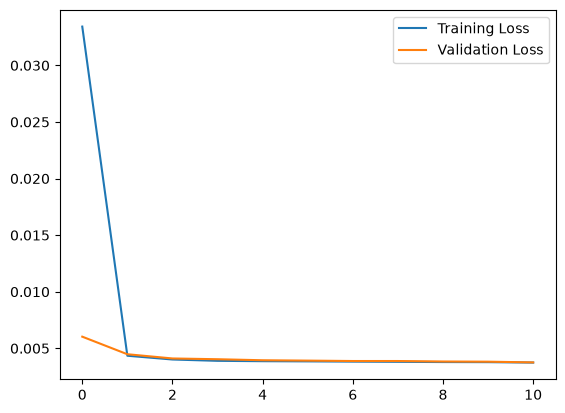

In [19]:
plt.plot(r.history['loss'])
plt.plot(r.history['val_loss'])
plt.legend(['Training Loss', 'Validation Loss'])
plt.show()